In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.multivariate.factor import Factor
from factor_analyzer.factor_analyzer import calculate_kmo
from factor_analyzer.factor_analyzer import calculate_bartlett_sphericity
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import KMeans


In [2]:
df = pd.read_excel("case_data.xlsx")
df.head()

,X1,X2,X3,X4,X5,Y
0,1.59,0.26,2.05,0.32,0.14,9.7
1,0.34,0.28,0.46,0.59,0.66,8.4
2,2.53,0.31,2.46,0.30,0.31,9.0
3,4.63,0.40,6.44,0.43,0.59,9.9
4,2.16,0.26,2.16,0.39,0.16,9.6


In [3]:
std_df = df.copy()

for col in std_df.columns:
    std_df[col] = (std_df[col] - std_df[col].mean()) / std_df[col].std()

std_df.head()

,X1,X2,X3,X4,X5,Y
0,0.081190,-0.600043,0.215920,-0.452940,-0.661092,0.160739
1,-0.939058,-0.081824,-0.759110,0.365222,1.951543,-0.512186
2,0.848417,0.695505,0.467344,-0.513544,0.193039,-0.201605
3,2.562435,3.027492,2.907987,-0.119614,1.599843,0.264266
4,0.546424,-0.600043,0.283375,-0.240824,-0.560606,0.108976


In [4]:
chi_square_value, p_value = calculate_bartlett_sphericity(std_df)
chi_square_value, p_value

(82.82808425534758, 2.11551379313073e-11)

In [5]:
kmo_all, kmo_model = calculate_kmo(std_df)
kmo_model

0.5980252886824298

In [6]:
fa = Factor(std_df[std_df.columns[:5]], n_factor = 2, method = "pa")
res = fa.fit()

In [7]:
res.rotate(method = "varimax")
res.get_loadings_frame()

,factor 0,factor 1
X3,1.003659,-0.064785
X1,0.903583,-0.251059
X2,0.861548,-0.218004
X5,0.232090,-0.911640
X4,0.057517,-0.613752


In [8]:
ev = res.eigenvals


In [9]:
len(ev)

5

In [35]:
std_df.shape[1]-1

5

In [29]:
range(1, std_df.shape[1]+1)

range(1, 7)

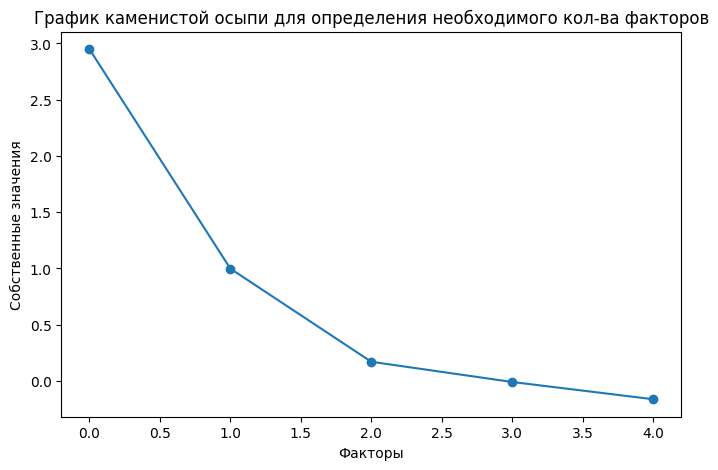

In [10]:
plt.close()

plt.figure(figsize=(8, 5))
plt.scatter(range(0, std_df.shape[1] - 1), ev)
plt.plot(range(0, std_df.shape[1] - 1), ev)
plt.title('График каменистой осыпи для определения необходимого кол-ва факторов')
plt.xlabel('Факторы')
plt.ylabel('Собственные значения')

plt.savefig("stones.png")

In [21]:
res.summary()

<class 'statsmodels.iolib.summary2.Summary'>
"""
       Factor analysis results
=====================================
          Eigenvalues                
-------------------------------------
   x1     x2     x3      x4      x5  
-------------------------------------
 2.8588 1.3069 0.0858 -0.0033 -0.0861
-------------------------------------
                                     
-------------------------------------
          Communality                
-------------------------------------
     x1     x2     x3     x4     x5  
-------------------------------------
   0.9565 0.7974 1.0044 0.3685 1.0390
-------------------------------------
                                     
-------------------------------------
       Pre-rotated loadings          
------------------------------------------------------
                    factor 0                  factor 1
------------------------------------------------------
x1                    0.9653                    0.1572
x2                    0.8883                    0.0917
x3                    0.9652                    0.2696
x4                    0.1860                   -0.5779
x5                    0.4145                   -0.9312
-------------------------------------
                                     
-------------------------------------
     varimax rotated loadings        
------------------------------------------------------
                    factor 0                  factor 1
------------------------------------------------------
x1                    0.9696                   -0.1278
x2                    0.8770                   -0.1683
x3                    1.0020                   -0.0202
x4                    0.0115                   -0.6069
x5                    0.1284                   -1.0112
=====================================

"""

In [22]:
res.loadings

array([[ 0.9696029 , -0.12777353],
       [ 0.87698495, -0.16825232],
       [ 1.00197759, -0.02015168],
       [ 0.01145807, -0.60694995],
       [ 0.12839042, -1.0111706 ]])

In [11]:
pd.DataFrame(res.loadings).to_excel("loadings.xlsx")

In [12]:
pd.DataFrame(std_df).to_excel("std_df.xlsx")

In [13]:
pces = np.dot(std_df[std_df.columns[:5]], res.loadings)
pc1 = []
pc2 = []

for i in pces:
    print
    pc1.append(i[0])
    pc2.append(i[1])

In [14]:
pces.T[0]

array([-0.4063784 , -1.20695967,  1.85014417,  8.20675551,  0.11722226,
        1.33582407, -0.94625228, -2.41323659, -2.69299195,  3.52743372,
        1.43476721,  2.28754978,  0.38734461, -1.15484384, -2.47800686,
       -0.16611411, -3.54737875, -2.8450697 , -1.28980919])

In [15]:
pces = pd.DataFrame({"PC1": pces.T[0], "PC2": pces.T[1]})
pces

,PC1,PC2
0,-0.406378,0.977110
1,-1.206960,-1.700484
2,1.850144,-0.255696
3,8.206756,-2.876788
4,0.117222,0.634146
5,1.335824,0.471525
6,-0.946252,-0.147096
7,-2.413237,1.775360
8,-2.692992,1.869315
9,3.527434,-4.374058


In [16]:
sk_ac = AgglomerativeClustering(n_clusters=3, linkage='ward')
sk_ac_pred_res = sk_ac.fit_predict(pces)

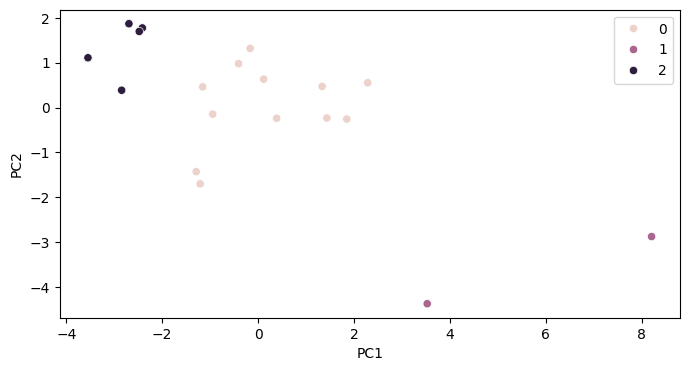

In [17]:
plt.close()
plt.figure(figsize=(8,4))
sns.scatterplot(data = pces, x = "PC1", y = "PC2", hue = sk_ac_pred_res)
plt.savefig("scatter.png")

In [24]:
ward_df = pces.copy()
ward_df["Y"] = std_df["Y"]
ward_df["clusters"] = sk_ac_pred_res
ward_df.to_excel("ward.xlsx")

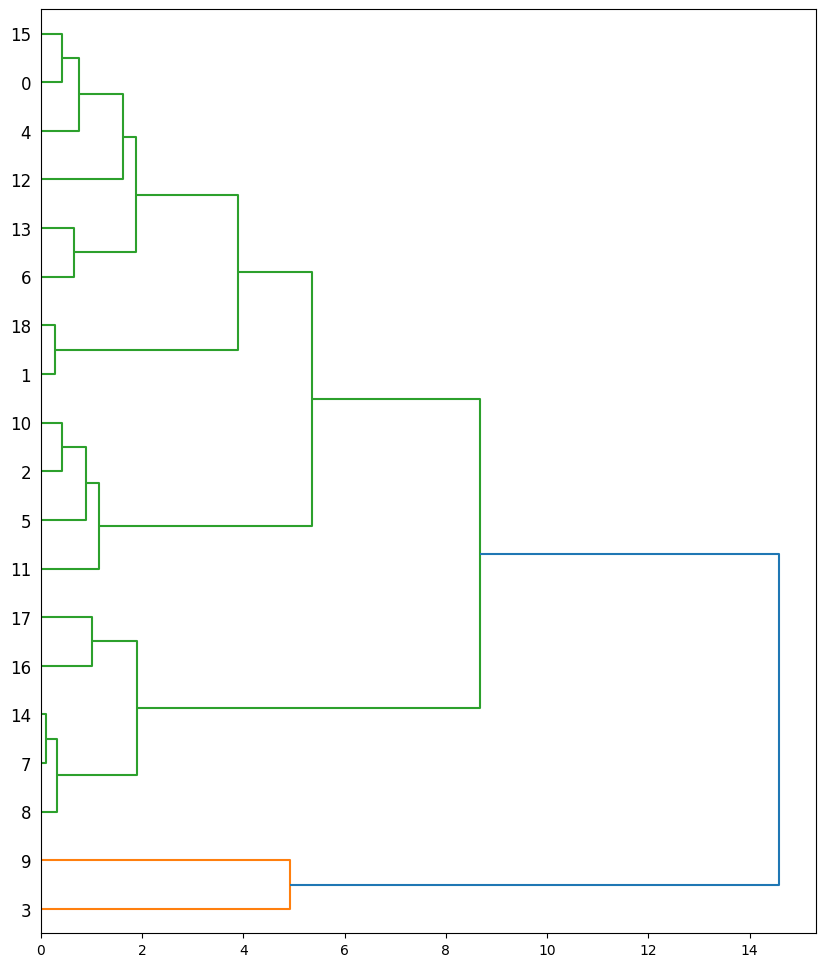

In [19]:
Z = linkage(pces[["PC1", "PC2"]], method='ward', metric='euclidean')

plt.close()
plt.figure(figsize=(10, 12))
dendrogram(Z, color_threshold=10, orientation="right", labels = pces.index)
plt.savefig("dendro.png")

In [20]:
kmeans = KMeans(n_clusters=3)
k_means_predict = kmeans.fit_predict(std_df[std_df.columns[:2]])

In [80]:
k_means_predict

array([3, 3, 1, 3, 1, 3, 3, 0, 1, 1, 1, 2, 3, 3, 3, 1, 0, 0, 3],
      dtype=int32)

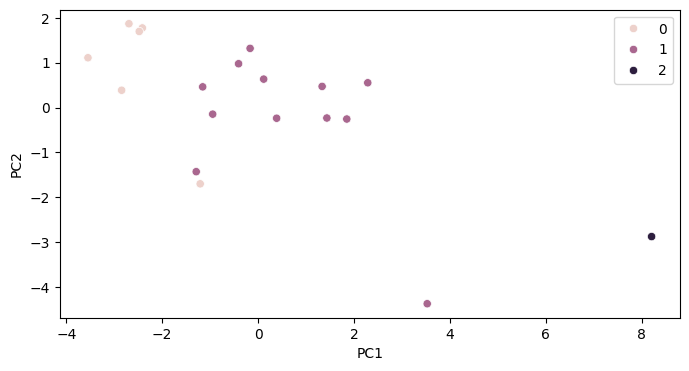

In [21]:
plt.close()
plt.figure(figsize=(8,4))
sns.scatterplot(data = pces, x = "PC1", y = "PC2", hue = k_means_predict)
plt.savefig("scatter_k_means.png")

In [23]:
kmeans_df = pces.copy()
kmeans_df["Y"] = std_df["Y"]
kmeans_df["clusters"] = k_means_predict
kmeans_df.to_excel("kmeans.xlsx")